# 05.3 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/05-powerful-models/03-boosting-by-hand/solutions.ipynb)

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

five = pd.read_csv(data_path("shopwave_visits_spend_5.csv"))
x = five["visits_last_month"].to_numpy(dtype=float)
y = five["spend_next_month"].to_numpy(dtype=float)
five

def best_stump(x, r):
    """Try every split between neighbouring x values; return (threshold, left mean, right mean, SSE)."""
    xs = np.unique(x)
    best = None
    for t in (xs[:-1] + xs[1:]) / 2:
        left, right = r[x <= t], r[x > t]
        sse = ((left - left.mean())**2).sum() + ((right - right.mean())**2).sum()
        if best is None or sse < best[3]:
            best = (t, left.mean(), right.mean(), sse)
    return best

## Exercise 1

Same split as before ($x \le 7$, leaf means −26.67 and 40), but now we add the whole correction:

- $x \le 7$: $100 - 26.67 = 73.33$; $x > 7$: $100 + 40 = 140$.
- Residuals: $-23.33, 6.67, 16.67, -10, 10$. SSE $= 544.4 + 44.4 + 277.8 + 100 + 100 = 1066.7$.

That is exactly the stump's own SSE from the README table, as it must be: with $\nu = 1$ the ensemble *is* mean + stump.

In [2]:
def boost(x, y, lr, rounds):
    F = np.full_like(y, y.mean()); sse = []
    for _ in range(rounds):
        t, lm, rm, _ = best_stump(x, y - F)
        F = F + lr * np.where(x <= t, lm, rm)
        sse.append(((y - F)**2).sum())
    return F, sse

for lr in [1.0, 0.5]:
    _, sse = boost(x, y, lr, 3)
    print(f"lr={lr}: SSE after 1 round {sse[0]:.1f}, after 3 rounds {sse[2]:.1f}")

lr=1.0: SSE after 1 round 1066.7, after 3 rounds 272.7
lr=0.5: SSE after 1 round 2400.0, after 3 rounds 534.0


The full step wins on the training data after one round and after three. That is expected: shrinkage is not there to fit the training data faster but to **generalise** better, by not trusting any single tree too much. On five rows with no test set, there is nothing to generalise to.

## Exercise 2

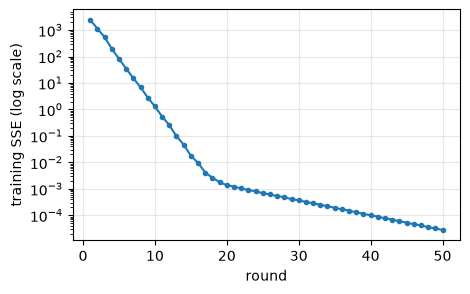

SSE after 50 rounds: 0.000028


In [3]:
_, sse = boost(x, y, 0.5, 50)
plt.figure(figsize=(5, 3)); plt.plot(range(1, 51), sse, marker=".")
plt.yscale("log"); plt.xlabel("round"); plt.ylabel("training SSE (log scale)"); plt.grid(alpha=.3); plt.show()
print(f"SSE after 50 rounds: {sse[-1]:.6f}")

SSE falls towards zero: with enough stumps the staircase passes through every point. On five customers that means memorising them, including any noise in their spend. Training error near zero is the overfitting signature from 02.6; what matters is error on customers the model has not seen.

## Exercise 3

$\alpha = \tfrac12 \ln\frac{0.7}{0.3} = \tfrac12 \ln 2.333 = \tfrac12 \times 0.847 = 0.424$. Misclassified weights are multiplied by $e^{0.424} = 1.53$; correct ones by $e^{-0.424} = 0.65$.

In [4]:
eps = 0.3
alpha = 0.5 * np.log((1 - eps) / eps)
print(f"alpha = {alpha:.3f}, wrong rows x{np.exp(alpha):.2f}, right rows x{np.exp(-alpha):.2f}")

alpha = 0.424, wrong rows x1.53, right rows x0.65


## Exercise 4

In [5]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail
from sklearn.model_selection import train_test_split

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]
cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

def cv_auc(model):
    """Mean 5-fold cross-validated AUC on the training customers."""
    return cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc").mean()

def test_auc(model):
    """Fit on all training customers, score AUC on the held-out test customers."""
    model.fit(X_train, y_train)
    return roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])

print(f"Benchmark logistic regression: CV AUC {cv_auc(logreg):.3f}, test AUC {test_auc(logreg):.3f}")

Benchmark logistic regression: CV AUC 0.740, test AUC 0.741


In [7]:
from sklearn.ensemble import GradientBoostingClassifier

def staged_test_auc(lr, n=500):
    gb = GradientBoostingClassifier(n_estimators=n, learning_rate=lr, max_depth=3, random_state=42)
    gb.fit(X_train, y_train)
    return [roc_auc_score(y_test, p[:, 1]) for p in gb.staged_predict_proba(X_test)]

for lr in [0.3, 0.1, 0.03]:
    curve = np.array(staged_test_auc(lr))
    best = int(curve.argmax()) + 1
    near = (curve >= curve.max() - 0.005).sum()
    print(f"lr={lr}: peak {curve.max():.3f} at round {best}; {near} of 500 rounds within 0.005 of the peak")

lr=0.3: peak 0.739 at round 6; 9 of 500 rounds within 0.005 of the peak


lr=0.1: peak 0.740 at round 15; 47 of 500 rounds within 0.005 of the peak


lr=0.03: peak 0.741 at round 51; 89 of 500 rounds within 0.005 of the peak


Read your output: the peak AUCs are close to each other, but the smallest learning rate keeps test AUC near its peak for many more rounds. That is why practitioners pair a **small learning rate** with **early stopping**: the result is good and not fragile to the exact number of trees. Remember this is a learning exercise; picking the round by looking at test AUC is cheating in a real project (05.4 uses a validation set).